# Inspect UCSF Patients

**Purpose:** Just like UTSW (`00_inspect_one_patient.ipynb`), we will look at one patient of the UCSF dataset to determine what files will be kept for the final test set and to inspect image quality and shape. 

From the UCSF download page, the first patient (UCSF-PDGM-0004_nifti) has +20 files. Not all those files will be needed. The UTSW dataset had 5 files per patient, the T1, T1ce, T2, FLAIR, and tumor segmentation. To make the UCSF dataset compatible with the models trained, these same 5 files are requried. The dataset also has a bias file for each contrast (i.e. T1 and T1_bias). From the dataset documentation and source paper, there is no explicit mention of the difference between the bias and non-bias file. This notebook will look at both to decide which to keep. 

Here we will look at patient 0004 and 0005. 

### Load patients, Shape, and Orientation

In [1]:
import nibabel as nib
from src.config import RAW_UCSF

# Set this to where you downloaded the patient folders
RAW = RAW_UCSF
patients = sorted(RAW.glob("UCSF-PDGM-*_nifti"))
print(patients)

names = ["T1", "T1c", "T2", "FLAIR", "T1_bias", "T1c_bias",
         "T2_bias", "FLAIR_bias", "tumor_segmentation"]

for p in patients:
    pid = p.name.replace("_nifti", "")
    print("\n", pid)
    for n in names:
        img = nib.load(p / f"{pid}_{n}.nii.gz")
        print(f"{n:20s} shape={img.shape} "
              f"voxel={tuple(round(float(z), 2) for z in img.header.get_zooms())} "
              f"orient={''.join(nib.aff2axcodes(img.affine))} "
              f"dtype={img.get_data_dtype()}")

[WindowsPath('C:/Users/javen/Projects/gliomas-idh-mri-prediction/Data/raw_ucsf/UCSF-PDGM-0004_nifti'), WindowsPath('C:/Users/javen/Projects/gliomas-idh-mri-prediction/Data/raw_ucsf/UCSF-PDGM-0005_nifti')]

 UCSF-PDGM-0004
T1                   shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
T1c                  shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
T2                   shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
FLAIR                shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
T1_bias              shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
T1c_bias             shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
T2_bias              shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
FLAIR_bias           shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LPS dtype=int16
tumor_segmentation   shape=(240, 240, 155) voxel=(1.0, 1.0, 1.0) orient=LP

### Intensities and Segmentation Labels
Here the minimum, maximum, and mean voxel intensities calculated and compared with the plain files against their bias contrasts. The segmentation lables were also looked at. 

In [2]:
import numpy as np

def load(p, pid, name):
    # keep native dtype (int16) to save RAM
    return np.asanyarray(nib.load(p / f"{pid}_{name}.nii.gz").dataobj)

for p in patients:
    pid = p.name.replace("_nifti", "")
    print("\n", pid)
    for c in ["T1", "T1c", "T2", "FLAIR"]:
        a, b = load(p, pid, c), load(p, pid, c + "_bias")
        na, nb = a != 0, b != 0
        print(f"{c:6s} plain: min={a.min()} max={a.max()} "
              f"nonzero={na.mean():.3f} mean_nz={a[na].mean():.1f} | "
              f"bias: min={b.min()} max={b.max()} "
              f"nonzero={nb.mean():.3f} mean_nz={b[nb].mean():.1f} | "
              f"same nonzero mask: {np.array_equal(na, nb)}")

    seg = load(p, pid, "tumor_segmentation")
    vals, counts = np.unique(seg, return_counts=True)
    print("seg labels:", dict(zip(vals.tolist(), counts.tolist())))
    brain = load(p, pid, "T1") != 0
    print("tumor voxels (label>0):", int((seg > 0).sum()),
          "| inside plain T1 nonzero:", f"{brain[seg > 0].mean():.4f}")


 UCSF-PDGM-0004
T1     plain: min=0.0 max=2563.6928141489625 nonzero=0.160 mean_nz=651.2 | bias: min=0.0 max=1283.4921339154243 nonzero=0.160 mean_nz=609.5 | same nonzero mask: True
T1c    plain: min=0.0 max=11736.999615803361 nonzero=0.160 mean_nz=2132.1 | bias: min=0.0 max=8809.044293537736 nonzero=0.160 mean_nz=1946.9 | same nonzero mask: True
T2     plain: min=0.0 max=2364.564749132842 nonzero=0.160 mean_nz=562.2 | bias: min=0.0 max=2018.7179756350815 nonzero=0.160 mean_nz=495.3 | same nonzero mask: True
FLAIR  plain: min=0.0 max=3333.392006792128 nonzero=0.160 mean_nz=1006.0 | bias: min=0.0 max=2942.3703855089843 nonzero=0.160 mean_nz=1099.3 | same nonzero mask: True
seg labels: {0: 8886081, 1: 7593, 2: 18654, 4: 15672}
tumor voxels (label>0): 41919 | inside plain T1 nonzero: 1.0000

 UCSF-PDGM-0005
T1     plain: min=0.0 max=1617.4566424358636 nonzero=0.146 mean_nz=705.7 | bias: min=0.0 max=1056.2497518025339 nonzero=0.146 mean_nz=653.4 | same nonzero mask: True
T1c    plain: min

### Visualize
The previous cell looked at the numerical differences between the plain and bias contrasts. Here the scans will be compared visually for a difference. Here the first patient (0004) is looked at. 

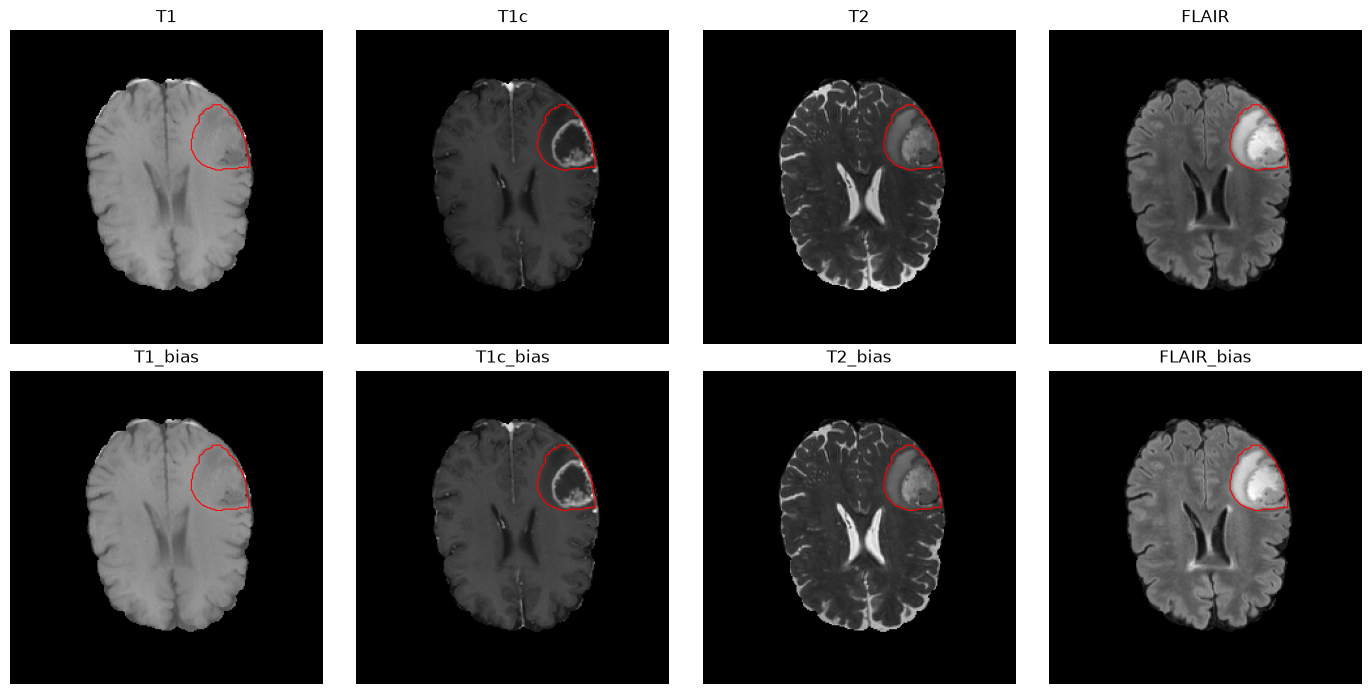

In [3]:
import matplotlib.pyplot as plt

p = patients[0]; pid = p.name.replace("_nifti", "")
seg = load(p, pid, "tumor_segmentation")
z = int(np.round(np.argwhere(seg > 0)[:, 2].mean()))   # slice through the tumor centre

fig, ax = plt.subplots(2, 4, figsize=(14, 7))
for j, c in enumerate(["T1", "T1c", "T2", "FLAIR"]):
    for i, suffix in enumerate(["", "_bias"]):
        img = load(p, pid, c + suffix)[:, :, z]
        ax[i, j].imshow(np.rot90(img), cmap="gray")
        ax[i, j].contour(np.rot90(seg[:, :, z] > 0), levels=[0.5], colors="r", linewidths=0.8)
        ax[i, j].set_title(c + suffix); ax[i, j].axis("off")
plt.tight_layout(); plt.show()

### Observations + Decision
The shape of the scans 240 x 240 x 155 and the orientation is LPS, this is identical to the UTSW dataset scans. The comparison between the plain and bias contrasts showed minimal differences. The bias has a lower maximum intensity and lower mean_nz, but visually the images are nearly identical. Thus, the plain contrasts will be used for the test set. 

### Preprocessing Check

The same preprocessing for UTSW will be applied here. Here is a quick check that the `preprocessing.py` works for UCSF, with the expected values. The shape of the processed image should be `[4, 128, 128, 128]` and the mean should be near 0 and std near 1. 

In [4]:
from src import preprocessing as pp

for p in patients:
    pid = p.name.replace("_nifti", "")
    r = pp.process_case(
        p,
        [f"{pid}_T1", f"{pid}_T1c", f"{pid}_T2", f"{pid}_FLAIR"],  # same order as UTSW
        f"{pid}_tumor_segmentation",
    )
    print(pid, r["image"].shape, r["image"].dtype, "bbox", r["bbox"],
          "mask_voxels", r["mask_voxels"], "tumor_in_brain", round(r["tumor_in_brain"], 4),
          "pieces", r["n_components"])
    img = r["image"].astype(np.float32)
    for c, name in enumerate(["T1", "T1c", "T2", "FLAIR"]):
        nz = img[c][img[c] != 0]
        print(f"   {name:5s} nonzero={float((img[c] != 0).mean()):.3f} "
              f"mean={nz.mean():.2f} sd={nz.std():.2f}")

UCSF-PDGM-0004 (4, 128, 128, 128) float16 bbox [44 50 46] mask_voxels 41919 tumor_in_brain 1.0 pieces 1
   T1    nonzero=0.396 mean=-0.02 sd=0.95
   T1c   nonzero=0.396 mean=0.12 sd=1.07
   T2    nonzero=0.396 mean=-0.12 sd=0.88
   FLAIR nonzero=0.396 mean=0.07 sd=1.04
UCSF-PDGM-0005 (4, 128, 128, 128) float16 bbox [49 54 58] mask_voxels 28419 tumor_in_brain 1.0 pieces 4
   T1    nonzero=0.459 mean=0.05 sd=1.00
   T1c   nonzero=0.459 mean=0.04 sd=1.03
   T2    nonzero=0.459 mean=-0.02 sd=1.00
   FLAIR nonzero=0.459 mean=-0.05 sd=0.96
